In [13]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from copy import deepcopy
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
## 1(c)

In [24]:
# Load data
df = pd.read_parquet("taxi_trips.parquet")

features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "min_of_day", "day_of_week", "day_of_year"
]

df = df.dropna(subset=features + ["trip_duration"])
X = df[features].to_numpy(dtype=np.float32)
y = df["trip_duration"].to_numpy(dtype=np.float32)

mask = np.isfinite(X).all(axis=1) & np.isfinite(y)
X, y = X[mask], y[mask]

# Train / validation / test split: 70% / 15% / 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Train:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))


Train: 366487
Validation: 78533
Test: 78534


In [21]:
# Gaussian negative log-likelihood
def gaussian_nll(y, mu, sigma):
    return np.mean(
        np.log(sigma)
        + 0.5 * ((y - mu) / sigma) ** 2
        + 0.5 * np.log(2 * np.pi)
    )


# Baseline 1: Constant Gaussian
mean_base = y_train.mean()
std_base = max(y_train.std(), 1e-6)

nll_base1 = gaussian_nll(y_val, mean_base, std_base)


# Baseline 2: Linear regression with constant variance
linear = LinearRegression()
linear.fit(X_train, y_train)

linear_train_pred = linear.predict(X_train)
linear_val_pred = linear.predict(X_val)

linear_std = max(
    np.sqrt(np.mean((y_train - linear_train_pred) ** 2)),
    1e-6
)

nll_base2 = gaussian_nll(y_val, linear_val_pred, linear_std)


# Gaussian MLP
class GaussianMLP(nn.Module):
    def __init__(self, input_dim, y_mean, y_std):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

        # Initialize outputs near the training-set mean and std
        with torch.no_grad():
            self.net[-1].bias.copy_(
                torch.tensor([y_mean, np.log(max(y_std, 1e-6))])
            )

    def forward(self, x):
        out = self.net(x)
        mu = out[:, 0]
        log_sigma = out[:, 1].clamp(-5, 8)
        return mu, log_sigma


# PyTorch loss
def nll_loss(mu, log_sigma, y):
    return (
        log_sigma
        + 0.5 * ((y - mu) * torch.exp(-log_sigma)) ** 2
        + 0.5 * np.log(2 * np.pi)
    ).mean()


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = GaussianMLP(
    input_dim=7,
    y_mean=float(y_train.mean()),
    y_std=float(y_train.std())
).to(device)

train_data = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)
train_loader = DataLoader(
    train_data, batch_size=512, shuffle=True
)

X_val_t = torch.from_numpy(X_val).to(device)
y_val_t = torch.from_numpy(y_val).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training with early stopping
best_val = float("inf")
best_state = None
patience = 8
wait = 0

train_losses = []
val_losses = []

for epoch in range(60):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        mu, log_sigma = model(xb)
        loss = nll_loss(mu, log_sigma, yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(y_train)

    model.eval()
    with torch.no_grad():
        mu_val, log_sigma_val = model(X_val_t)
        val_loss = nll_loss(
            mu_val, log_sigma_val, y_val_t
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_state = deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break

model.load_state_dict(best_state)
model.eval()

# Compare validation NLL
print(f"Constant Gaussian NLL: {nll_base1:.4f}")
print(f"Linear Gaussian NLL:   {nll_base2:.4f}")
print(f"Gaussian MLP NLL:      {best_val:.4f}")


Constant Gaussian NLL: 3.4661
Linear Gaussian NLL:   3.4369
Gaussian MLP NLL:      2.6284


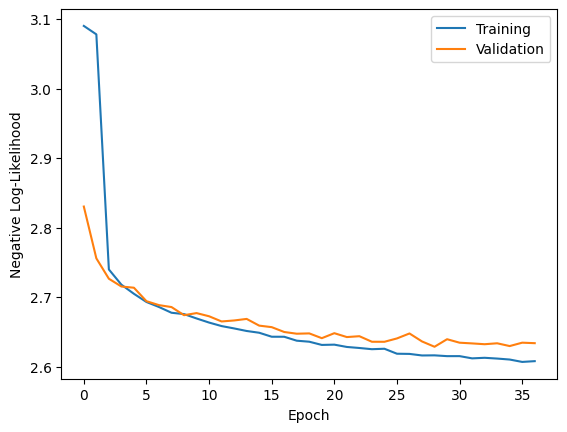

In [25]:
# Plot training and validation loss
plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Negative Log-Likelihood")
plt.legend()
plt.show()

The dataset was split into training (70%), validation (15%), and test (15%) sets. I trained a Gaussian MLP with two hidden layers of 64 units using Gaussian negative log-likelihood and early stopping. The validation NLLs were 3.4661 for the constant Gaussian baseline, 3.4369 for the linear Gaussian baseline, and 2.6284 for the MLP. The MLP achieved the lowest NLL, outperforming both baselines. The training and validation losses decreased steadily, with no significant overfitting observed.

In [27]:
# 1(e)
from sklearn.metrics import brier_score_loss, accuracy_score

# Predict probabilities on the test set
model.eval()

with torch.no_grad():
    X_test_t = torch.from_numpy(X_test).to(device)
    mu, log_sigma = model(X_test_t)
    sigma = torch.exp(log_sigma)

    z = (45 - mu) / sigma
    probabilities = torch.distributions.Normal(0, 1).cdf(z)
    probabilities = probabilities.cpu().numpy()
    
# True labels: 1 if trip duration < 45 minutes
y_true = (y_test < 45).astype(int)

# Predicted labels using threshold 0.5
y_pred = (probabilities >= 0.5).astype(int)

# Evaluation
brier = brier_score_loss(y_true, probabilities)
accuracy = accuracy_score(y_true, y_pred)

print(f"Test Brier Score: {brier:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Brier Score: 0.0030
Test Accuracy: 0.9964


In [ ]:
# 2(a)

In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(
    "retail.csv",
    dtype={"StockCode": str, "CustomerID": str}
)

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df = df.dropna(subset=["StockCode", "CustomerID", "Quantity"])
df = df[df["Quantity"] > 0].copy()

# Check cardinality
n_stock = df["StockCode"].nunique()
n_customer = df["CustomerID"].nunique()

print("StockCode unique values:", n_stock)
print("CustomerID unique values:", n_customer)
print("Total one-hot dimensions:", n_stock + n_customer)

# test split 70% /15% /15%
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

StockCode unique values: 3665
CustomerID unique values: 4339
Total one-hot dimensions: 8004
Train: 278546
Validation: 59689
Test: 59689


StockCode has 3665 unique values, and CustomerID has 4339, giving 8004 one-hot dimensions in total. One-hot encoding is feasible with sparse matrices, but it creates high-dimensional features. Target encoding and embeddings may be more efficient. The data was split into 70% training, 15% validation, and 15% test sets.

In [30]:
# 2(b)

In [31]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

cat_cols = ["StockCode", "CustomerID"]

def fit_encoding(data):
    global_mean = data["Quantity"].mean()
    mappings = {
        col: data.groupby(col)["Quantity"].mean()
        for col in cat_cols
    }
    return mappings, global_mean

def transform_encoding(data, mappings, global_mean):
    X = np.column_stack([
        data[col].map(mappings[col]).fillna(global_mean).to_numpy()
        for col in cat_cols
    ])
    return np.log1p(X)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
X_train_te = np.zeros((len(train_df), 2))

for train_idx, hold_idx in kf.split(train_df):
    fold_train = train_df.iloc[train_idx]
    fold_hold = train_df.iloc[hold_idx]

    mappings, global_mean = fit_encoding(fold_train)
    X_train_te[hold_idx] = transform_encoding(
        fold_hold, mappings, global_mean
    )

# Encode validation and test sets using training data
mappings, global_mean = fit_encoding(train_df)

X_val_te = transform_encoding(val_df, mappings, global_mean)
X_test_te = transform_encoding(test_df, mappings, global_mean)

# Log-transform target
y_train_log = np.log1p(train_df["Quantity"].to_numpy())
y_val_log = np.log1p(val_df["Quantity"].to_numpy())
y_test_log = np.log1p(test_df["Quantity"].to_numpy())

# Train model
te_model = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    early_stopping=True,
    random_state=42
)

te_model.fit(X_train_te, y_train_log)

# Evaluate
val_pred = te_model.predict(X_val_te)
test_pred = te_model.predict(X_test_te)

te_val_mae = mean_absolute_error(y_val_log, val_pred)
te_test_mae = mean_absolute_error(y_test_log, test_pred)

# MAE on original Quantity scale
test_pred_original = np.expm1(np.maximum(test_pred, 0))
te_test_mae_original = mean_absolute_error(
    test_df["Quantity"], test_pred_original
)

print(f"Validation Log-MAE: {te_val_mae:.4f}")
print(f"Test Log-MAE: {te_test_mae:.4f}")
print(f"Test Original MAE: {te_test_mae_original:.4f}")

Validation Log-MAE: 0.4537
Test Log-MAE: 0.4540
Test Original MAE: 6.9232


I used target encoding based on the mean Quantity for each category, with 5-fold encoding to avoid data leakage. Since Quantity is heavy-tailed, we applied a log1p transformation and trained a Histogram Gradient Boosting model with absolute error loss.

- **Validation Log-MAE:** 0.4537
- **Test Log-MAE:** 0.4540
- **Test Original MAE:** 6.9232

In [32]:
# 2(c)

In [35]:
import torch
import torch.nn as nn
from copy import deepcopy
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

stock_vocab = {
    v: i + 1 for i, v in enumerate(train_df["StockCode"].unique())
}
customer_vocab = {
    v: i + 1 for i, v in enumerate(train_df["CustomerID"].unique())
}

def encode_categories(data):
    return np.column_stack([
        data["StockCode"].map(stock_vocab).fillna(0).to_numpy(),
        data["CustomerID"].map(customer_vocab).fillna(0).to_numpy()
    ]).astype(np.int64)

X_train_emb = encode_categories(train_df)
X_val_emb = encode_categories(val_df)
X_test_emb = encode_categories(test_df)

# Log-transform target
y_train = np.log1p(train_df["Quantity"].to_numpy()).astype(np.float32)
y_val = np.log1p(val_df["Quantity"].to_numpy()).astype(np.float32)
y_test = np.log1p(test_df["Quantity"].to_numpy()).astype(np.float32)

# Define embedding model
class EmbeddingMLP(nn.Module):
    def __init__(self, n_stock, n_customer):
        super().__init__()
        self.stock_emb = nn.Embedding(n_stock + 1, 16)
        self.customer_emb = nn.Embedding(n_customer + 1, 16)

        self.net = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        stock = self.stock_emb(x[:, 0])
        customer = self.customer_emb(x[:, 1])
        x = torch.cat([stock, customer], dim=1)
        return self.net(x).squeeze(1)

emb_model = EmbeddingMLP(
    len(stock_vocab), len(customer_vocab)
).to(device)


train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train_emb, dtype=torch.long),
        torch.tensor(y_train, dtype=torch.float32)
    ),
    batch_size=1024,
    shuffle=True
)

X_val_t = torch.tensor(X_val_emb, dtype=torch.long).to(device)
y_val_t = torch.tensor(y_val, dtype=torch.float32).to(device)

optimizer = torch.optim.AdamW(
    emb_model.parameters(), lr=0.001, weight_decay=1e-4
)
loss_fn = nn.L1Loss()

# Training with early stopping
best_val = float("inf")
best_state = None
patience = 6
wait = 0

for epoch in range(50):
    emb_model.train()

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        pred = emb_model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()

    emb_model.eval()
    with torch.no_grad():
        val_pred = emb_model(X_val_t)
        val_loss = loss_fn(val_pred, y_val_t).item()

    if val_loss < best_val - 1e-4:
        best_val = val_loss
        best_state = deepcopy(emb_model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break

emb_model.load_state_dict(best_state)
emb_model.eval()

# Evaluate on test set
with torch.no_grad():
    X_test_t = torch.tensor(
        X_test_emb, dtype=torch.long
    ).to(device)

    emb_test_pred = emb_model(X_test_t).cpu().numpy()

emb_test_mae = mean_absolute_error(y_test, emb_test_pred)

emb_pred_original = np.expm1(np.maximum(emb_test_pred, 0))
emb_test_mae_original = mean_absolute_error(
    test_df["Quantity"], emb_pred_original
)

# Compare 
print(f"Embedding Validation Log-MAE: {best_val:.4f}")
print(f"Embedding Test Log-MAE:       {emb_test_mae:.4f}")
print(f"Embedding Test Original MAE:  {emb_test_mae_original:.4f}")
print()
print(f"Target Encoding Test Log-MAE: {te_test_mae:.4f}")
print(f"Embedding Test Log-MAE:       {emb_test_mae:.4f}")

Embedding Validation Log-MAE: 0.3528
Embedding Test Log-MAE:       0.3524
Embedding Test Original MAE:  5.8469

Target Encoding Test Log-MAE: 0.4540
Embedding Test Log-MAE:       0.3524


I trained a neural network with separate 16-dimensional embedding layers for StockCode and CustomerID, followed by an MLP with two hidden layers. I used log1p(Quantity), MAE loss, AdamW, and early stopping.

- **Embedding Validation Log-MAE:** 0.3528
- **Embedding Test Log-MAE:** 0.3524
- **Embedding Test Original MAE:** 5.8469
- **Target Encoding Test Log-MAE:** 0.4540

The embedding model outperformed the target encoding model, reducing the test Log-MAE from 0.4540 to 0.3524.

In [36]:
# 2(d)

In [39]:
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Standardize
scaler = StandardScaler()

X_train_te_scaled = scaler.fit_transform(X_train_te).astype(np.float32)
X_val_te_scaled = scaler.transform(X_val_te).astype(np.float32)
X_test_te_scaled = scaler.transform(X_test_te).astype(np.float32)

# Combined model
class CombinedMLP(nn.Module):
    def __init__(self, n_stock, n_customer):
        super().__init__()

        self.stock_emb = nn.Embedding(n_stock + 1, 16)
        self.customer_emb = nn.Embedding(n_customer + 1, 16)

        self.net = nn.Sequential(
            nn.Linear(34, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x_cat, x_te):
        stock = self.stock_emb(x_cat[:, 0])
        customer = self.customer_emb(x_cat[:, 1])

        x = torch.cat([stock, customer, x_te], dim=1)
        return self.net(x).squeeze(1)


combined_model = CombinedMLP(
    len(stock_vocab), len(customer_vocab)
).to(device)


combined_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train_emb, dtype=torch.long),
        torch.tensor(X_train_te_scaled, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    ),
    batch_size=1024,
    shuffle=True
)

X_val_cat_t = torch.tensor(
    X_val_emb, dtype=torch.long
).to(device)

X_val_te_t = torch.tensor(
    X_val_te_scaled, dtype=torch.float32
).to(device)

y_val_t = torch.tensor(
    y_val, dtype=torch.float32
).to(device)

optimizer = torch.optim.AdamW(
    combined_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

loss_fn = nn.L1Loss()

# Training with early stopping
best_val = float("inf")
best_state = None
patience = 6
wait = 0

for epoch in range(50):
    combined_model.train()

    for x_cat, x_te, yb in combined_loader:
        x_cat = x_cat.to(device)
        x_te = x_te.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        pred = combined_model(x_cat, x_te)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()

    combined_model.eval()

    with torch.no_grad():
        val_pred = combined_model(X_val_cat_t, X_val_te_t)
        val_loss = loss_fn(val_pred, y_val_t).item()

    if val_loss < best_val - 1e-4:
        best_val = val_loss
        best_state = deepcopy(combined_model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break

combined_model.load_state_dict(best_state)
combined_model.eval()

# Evaluate on test set
with torch.no_grad():
    X_test_cat_t = torch.tensor(
        X_test_emb, dtype=torch.long
    ).to(device)

    X_test_te_t = torch.tensor(
        X_test_te_scaled, dtype=torch.float32
    ).to(device)

    combined_test_pred = combined_model(
        X_test_cat_t, X_test_te_t
    ).cpu().numpy()

combined_test_mae = mean_absolute_error(
    y_test, combined_test_pred
)

combined_pred_original = np.expm1(
    np.maximum(combined_test_pred, 0)
)

combined_test_mae_original = mean_absolute_error(
    test_df["Quantity"], combined_pred_original
)

# Compare all three models
print(f"Combined Validation Log-MAE: {best_val:.4f}")
print(f"Combined Test Log-MAE:       {combined_test_mae:.4f}")
print(f"Combined Test Original MAE:  {combined_test_mae_original:.4f}")

print("Model Comparison (Test Log-MAE)")
print(f"Target Encoding: {te_test_mae:.4f}")
print(f"Embedding:       {emb_test_mae:.4f}")
print(f"Combined:        {combined_test_mae:.4f}")

Combined Validation Log-MAE: 0.3507
Combined Test Log-MAE:       0.3502
Combined Test Original MAE:  5.7200
Model Comparison (Test Log-MAE)
Target Encoding: 0.4540
Embedding:       0.3524
Combined:        0.3502


I combined target-encoded features with two 16-dimensional embeddings in an MLP, which used log1p(Quantity), MAE loss, AdamW, and early stopping.

- **Combined Validation Log-MAE:** 0.3507
- **Combined Test Log-MAE:** 0.3502
- **Combined Test Original MAE:** 5.7200

**Test Log-MAE Comparison:**
- Target Encoding: 0.4540
- Embedding: 0.3524
- Combined: 0.3502

The combined model achieved the lowest test Log-MAE, slightly outperforming the embedding-only model and clearly outperforming the target encoding model.

In [40]:
# 2(e)

Embedding layers convert categorical variables into low-dimensional, trainable vectors. They learn useful patterns and relationships between different categories during training. Embeddings are useful here because StockCode and CustomerID have high cardinality. They can capture more information than target encoding, which only uses the mean target value for each category.

**Test Log-MAE Comparison:**
- Target Encoding: 0.4540
- Embedding: 0.3524
- Combined: 0.3502

The embedding model performed much better than target encoding. The combined model achieved the lowest error, but the improvement over embeddings alone was small. This suggests that embeddings already capture most of the useful information, while target encoding provides a small additional benefit.

In [41]:
# 3(a)

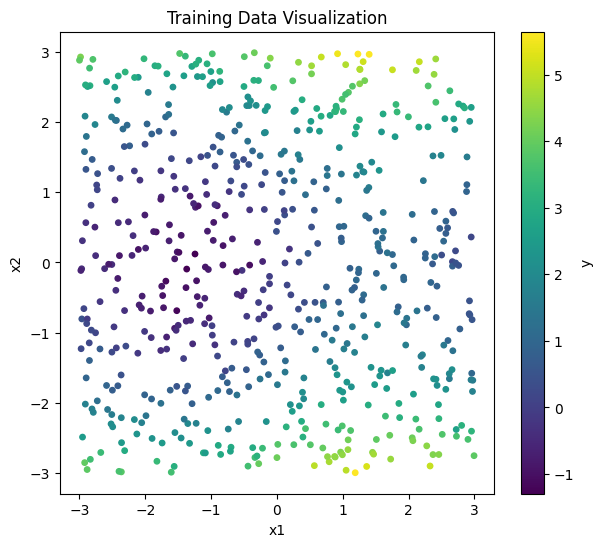

In [45]:
train = pd.read_csv("train.csv")

plt.figure(figsize=(7, 6))

sc = plt.scatter(
    train.iloc[:, 0],
    train.iloc[:, 1],
    c=train.iloc[:, 2],
    cmap="viridis",
    s=15
)

plt.colorbar(sc, label="y")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training Data Visualization")
plt.show()

In [46]:
# 3(b)

Best lambda: 2.371374
Training MSE: 0.0306
Validation MSE: 0.0384


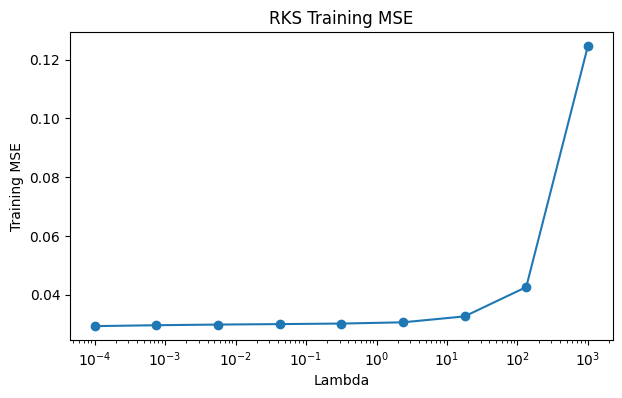

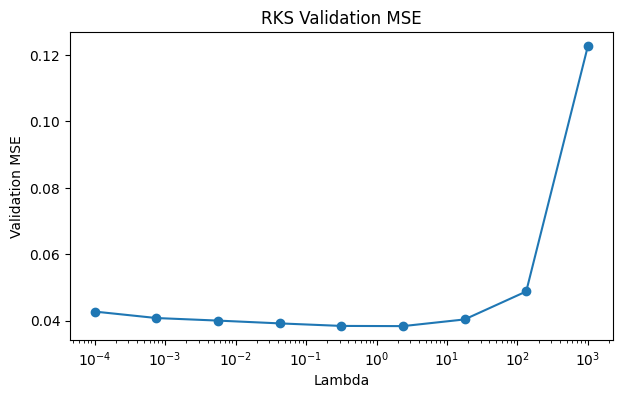

In [48]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

train_rks = pd.read_csv("train.csv")
val_rks = pd.read_csv("val.csv")

X_train_rks = train_rks.iloc[:, :2].to_numpy()
y_train_rks = train_rks.iloc[:, 2].to_numpy()
X_val_rks = val_rks.iloc[:, :2].to_numpy()
y_val_rks = val_rks.iloc[:, 2].to_numpy()


np.random.seed(42)

h = 150
sigma = 1.0

W = np.random.normal(0, 1 / sigma, size=(2, h))
b = np.random.uniform(0, 2 * np.pi, size=h)

def rks_features(X):
    projection = X @ W + b
    return np.stack(
        [np.sin(projection), np.cos(projection)], axis=-1
    ).reshape(len(X), -1)

Z_train = rks_features(X_train_rks)
Z_val = rks_features(X_val_rks)

# ridge regularization
lambdas = np.logspace(-4, 3, 9)

train_mse = []
val_mse = []

for lam in lambdas:
    model_ridge = Ridge(alpha=lam)
    model_ridge.fit(Z_train, y_train_rks)

    train_pred = model_ridge.predict(Z_train)
    val_pred = model_ridge.predict(Z_val)

    train_mse.append(mean_squared_error(y_train_rks, train_pred))
    val_mse.append(mean_squared_error(y_val_rks, val_pred))

# best lambda
best_idx = np.argmin(val_mse)
best_lambda = lambdas[best_idx]

print(f"Best lambda: {best_lambda:.6f}")
print(f"Training MSE: {train_mse[best_idx]:.4f}")
print(f"Validation MSE: {val_mse[best_idx]:.4f}")


rks_model = Ridge(alpha=best_lambda)
rks_model.fit(Z_train, y_train_rks)

# Plot 
plt.figure(figsize=(7, 4))
plt.semilogx(lambdas, train_mse, marker="o")
plt.xlabel("Lambda")
plt.ylabel("Training MSE")
plt.title("RKS Training MSE")
plt.show()


plt.figure(figsize=(7, 4))
plt.semilogx(lambdas, val_mse, marker="o")
plt.xlabel("Lambda")
plt.ylabel("Validation MSE")
plt.title("RKS Validation MSE")
plt.show()

I implemented RKS with 150 pairs of random sinusoidal features and ridge regression. I fixed $\sigma=1$ and varied $\lambda$.

- **Best $\lambda$:** 2.371374
- **Training MSE:** 0.0306
- **Validation MSE:** 0.0384

The validation MSE first decreases and then increases as $\lambda$ grows. Large values of $\lambda$ lead to underfitting. We selected $\lambda=2.371374$ based on the lowest validation MSE.

In [49]:
# 3(c)

Best hidden dimension: 128
Training MSE: 0.0334
Validation MSE: 0.0370


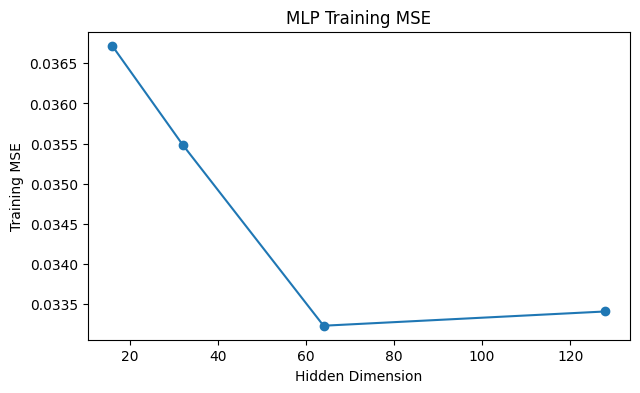

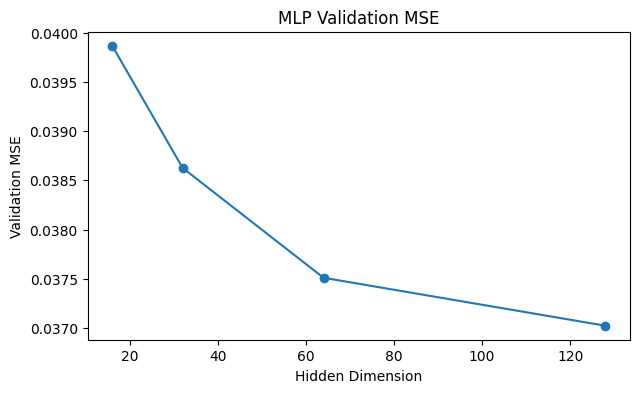

In [51]:
import torch
import torch.nn as nn
from copy import deepcopy

train_mlp_df = pd.read_csv("train.csv")
val_mlp_df = pd.read_csv("val.csv")

X_train_mlp = torch.tensor(
    train_mlp_df[["x1", "x2"]].to_numpy(), dtype=torch.float32
)
y_train_mlp = torch.tensor(
    train_mlp_df["y"].to_numpy(), dtype=torch.float32
).view(-1, 1)

X_val_mlp = torch.tensor(
    val_mlp_df[["x1", "x2"]].to_numpy(), dtype=torch.float32
)
y_val_mlp = torch.tensor(
    val_mlp_df["y"].to_numpy(), dtype=torch.float32
).view(-1, 1)



def fit_mlp(hidden_dim):
    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(2, hidden_dim),
        nn.Tanh(),
        nn.Linear(hidden_dim, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()

    best_val = float("inf")
    best_state = None
    patience = 80
    wait = 0

    for epoch in range(800):
        model.train()

        optimizer.zero_grad()
        loss = loss_fn(model(X_train_mlp), y_train_mlp)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(
                model(X_val_mlp), y_val_mlp
            ).item()

        if val_loss < best_val - 1e-6:
            best_val = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        train_mse = loss_fn(
            model(X_train_mlp), y_train_mlp
        ).item()
        val_mse = loss_fn(
            model(X_val_mlp), y_val_mlp
        ).item()

    return model, train_mse, val_mse


# Hyperparameter sweep
hidden_dims = [16, 32, 64, 128]

mlp_train_mse = []
mlp_val_mse = []

best_mlp_val = float("inf")
best_hidden = None
best_mlp_model = None

for dim in hidden_dims:
    model, train_err, val_err = fit_mlp(dim)

    mlp_train_mse.append(train_err)
    mlp_val_mse.append(val_err)

    if val_err < best_mlp_val:
        best_mlp_val = val_err
        best_hidden = dim
        best_mlp_model = model

print(f"Best hidden dimension: {best_hidden}")
print(f"Training MSE: {mlp_train_mse[hidden_dims.index(best_hidden)]:.4f}")
print(f"Validation MSE: {best_mlp_val:.4f}")


# Plot training MSE
plt.figure(figsize=(7, 4))
plt.plot(hidden_dims, mlp_train_mse, marker="o")
plt.xlabel("Hidden Dimension")
plt.ylabel("Training MSE")
plt.title("MLP Training MSE")
plt.show()


# Plot validation MSE
plt.figure(figsize=(7, 4))
plt.plot(hidden_dims, mlp_val_mse, marker="o")
plt.xlabel("Hidden Dimension")
plt.ylabel("Validation MSE")
plt.title("MLP Validation MSE")
plt.show()

I trained a one-hidden-layer MLP with Tanh activation and varied the hidden dimension over 16, 32, 64, and 128. I used Adam with a learning rate of 0.01, MSE loss, and early stopping.

- **Best Hidden Dimension:** 128
- **Training MSE:** 0.0334
- **Validation MSE:** 0.0370

The validation MSE decreased as the hidden dimension increased. We selected 128 hidden units because it achieved the lowest validation MSE.

In [52]:
# 3(d)

RKS Validation MSE: 0.0384
MLP Validation MSE: 0.0370
RKS predictions: 200
MLP predictions: 200


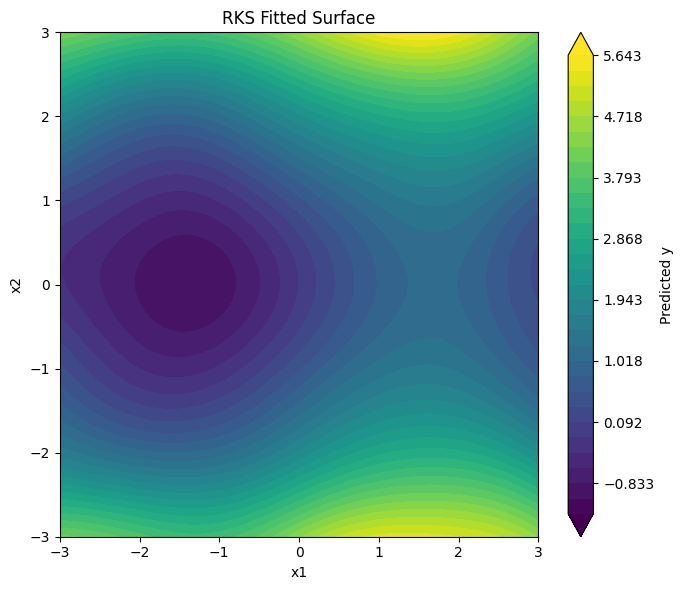

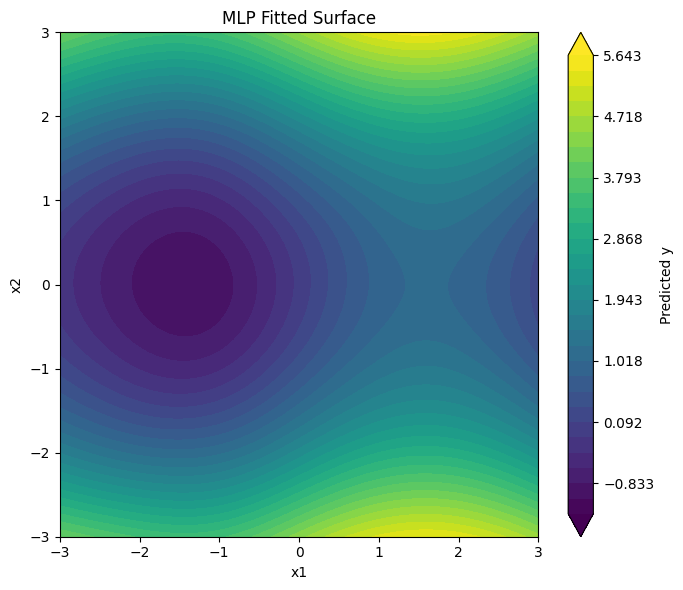

In [54]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

rks_model = Ridge(alpha=best_lambda)
rks_model.fit(rks_features(X_train_rks), y_train_rks)

best_mlp_model, _, _ = fit_mlp(best_hidden)
best_mlp_model.eval()

# Validation MSE
rks_val_pred = rks_model.predict(rks_features(X_val_rks))

with torch.no_grad():
    mlp_val_pred = best_mlp_model(
        X_val_mlp
    ).cpu().numpy().ravel()

rks_val_mse = mean_squared_error(y_val_rks, rks_val_pred)
mlp_val_mse = mean_squared_error(
    y_val_mlp.numpy().ravel(), mlp_val_pred
)

print(f"RKS Validation MSE: {rks_val_mse:.4f}")
print(f"MLP Validation MSE: {mlp_val_mse:.4f}")

# test predictions
test_q3 = pd.read_csv("test.csv")
X_test_q3 = test_q3[["x1", "x2"]].to_numpy()

rks_test_pred = rks_model.predict(rks_features(X_test_q3))

with torch.no_grad():
    mlp_test_pred = best_mlp_model(
        torch.tensor(X_test_q3, dtype=torch.float32)
    ).cpu().numpy().ravel()

# predictions
np.savetxt(
    "rks_test_predictions.csv",
    rks_test_pred,
    delimiter=",",
    fmt="%.10f"
)

np.savetxt(
    "mlp_test_predictions.csv",
    mlp_test_pred,
    delimiter=",",
    fmt="%.10f"
)

print("RKS predictions:", len(rks_test_pred))
print("MLP predictions:", len(mlp_test_pred))

# Visualize 
axis = np.linspace(-3, 3, 150)
x1, x2 = np.meshgrid(axis, axis)
grid = np.column_stack([x1.ravel(), x2.ravel()])

rks_grid_pred = rks_model.predict(rks_features(grid))

with torch.no_grad():
    mlp_grid_pred = best_mlp_model(
        torch.tensor(grid, dtype=torch.float32)
    ).cpu().numpy().ravel()

levels = np.linspace(y_train_rks.min(), y_train_rks.max(), 31)

for title, pred, filename in [
    ("RKS Fitted Surface", rks_grid_pred, "rks_surface.png"),
    ("MLP Fitted Surface", mlp_grid_pred, "mlp_surface.png")
]:
    plt.figure(figsize=(7, 6))
    contour = plt.contourf(
        x1, x2, pred.reshape(x1.shape),
        levels=levels, cmap="viridis", extend="both"
    )
    plt.colorbar(contour, label="Predicted y")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

I refitted both models using their best hyperparameters.

- **RKS Validation MSE:** 0.0384
- **MLP Validation MSE:** 0.0370

The MLP performed slightly better than RKS. This may be because the MLP learns nonlinear features from the data, while RKS uses fixed random features. Both fitted surfaces capture the main nonlinear patterns in the training data, including the low values around the left-center region and higher values near the top and bottom. The two surfaces are very similar, but the MLP has a slightly lower validation error.

I also generated 200 test predictions for each model and saved them in `rks_test_predictions.csv` and `mlp_test_predictions.csv`.